# 1.01 Temporal Patterns Analysis — José Eduardo De Moraes López

## 1. Objective
Analyze how trip departures vary across hours of the day, days of the week, and their interaction, in order to evaluate whether defining the predictive model at a **station × hour** granularity is justified.

## 2. Research Questions
1. At what hours are trip departures most heavily concentrated?
2. Are there distinct morning and evening peak hours?
3. How do departure profiles differ between weekdays and weekends?
4. Are there notable differences across individual days of the week?
5. Is the hourly departure profile stable over time to justify a station × hour modeling unit?

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import gc

# Visualization styling setup
sns.set_theme(style="whitegrid")
plt.rcParams["font.size"] = 11

# Resolve project root dynamically regardless of execution context
CURRENT_DIR = Path.cwd()
PROJ_ROOT = (
    CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
)

# Output directory for reporting figures
FIGURES_DIR = PROJ_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Data input path
DATA_PATH = PROJ_ROOT / "data" / "interim" / "trips"
print(f"Data directory: {DATA_PATH.resolve()}")
print(f"Dataset available: {DATA_PATH.exists()}")

Data directory: C:\Users\lalo4\MiBici\data\interim\trips
Dataset available: True


In [2]:
# Load lightweight pre-aggregated summary dataset (~1 MB)
SUMMARY_PATH = PROJ_ROOT / "data" / "interim" / "temporal_summary.parquet"

hourly_counts = pd.read_parquet(SUMMARY_PATH)
hourly_counts["is_weekend"] = hourly_counts["dayofweek"] >= 5

print(f"Loaded {len(hourly_counts):,} daily-hourly records.")
print(f"RAM footprint: {hourly_counts.memory_usage().sum() / 1e6:.2f} MB")

Loaded 61,906 daily-hourly records.
RAM footprint: 1.30 MB


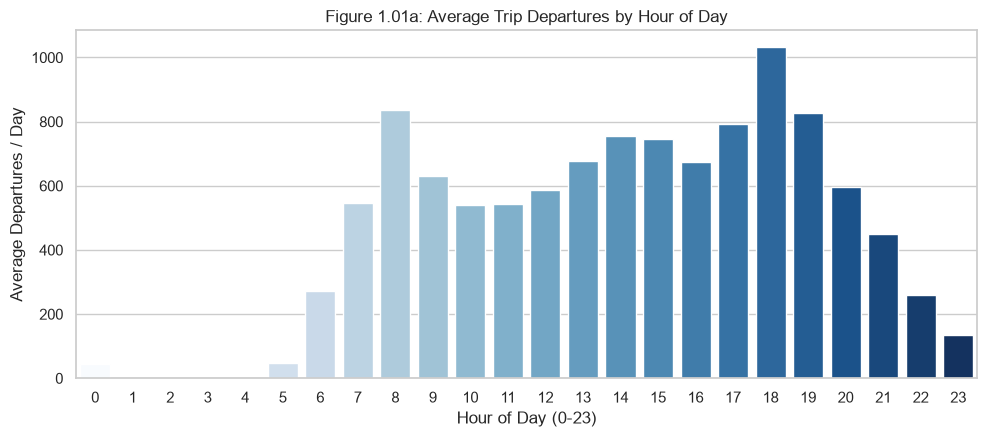

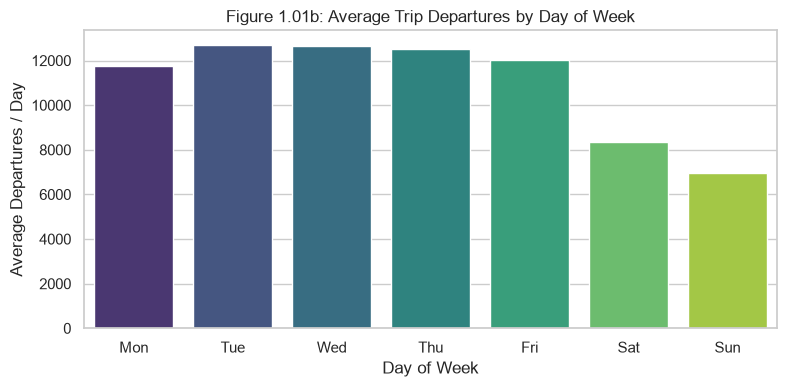

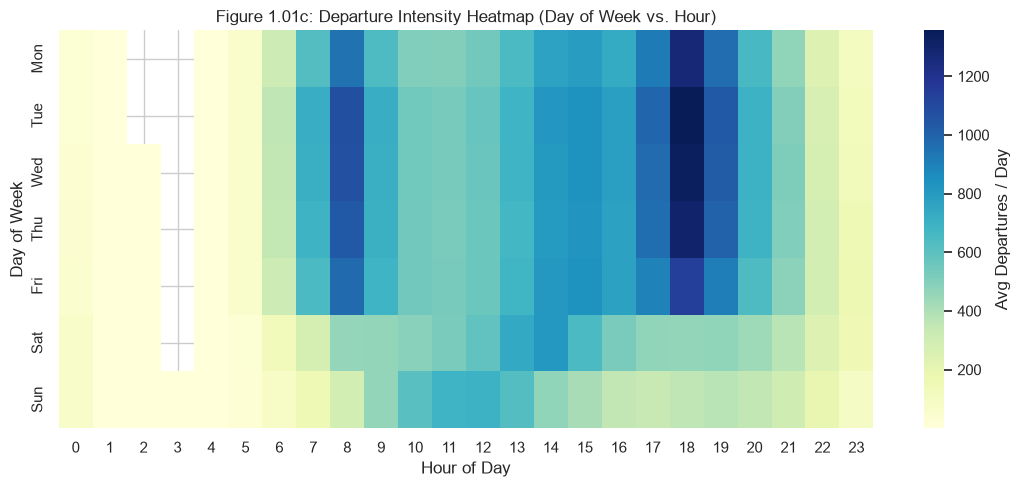

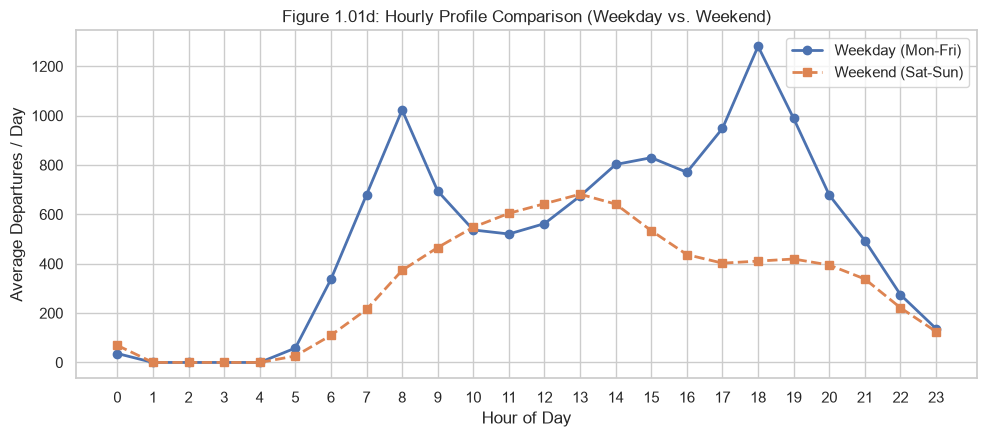

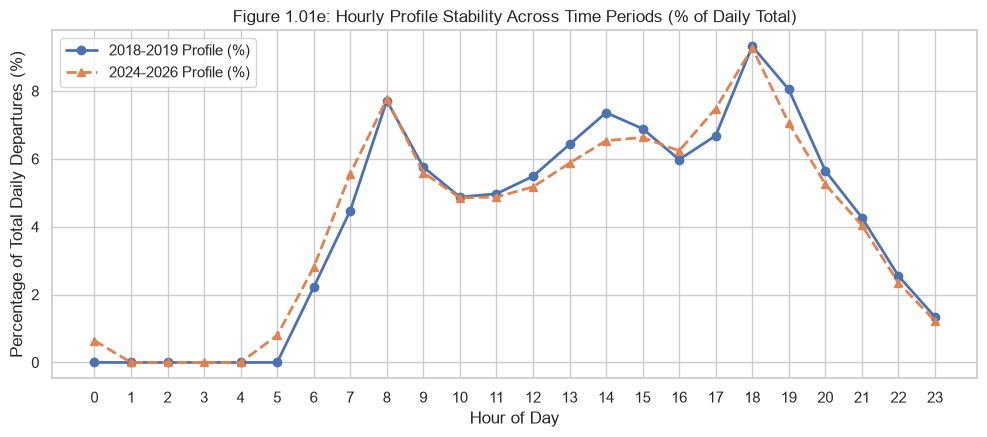

In [3]:
# Compute temporal metrics from summary table
total_dates = hourly_counts["date"].nunique()
dates_per_dow = hourly_counts.groupby("dayofweek")["date"].nunique()
weekday_dates = hourly_counts[~hourly_counts["is_weekend"]][
    "date"
].nunique()
weekend_dates = hourly_counts[hourly_counts["is_weekend"]]["date"].nunique()

hourly_avg = hourly_counts.groupby("hour")["trip_count"].sum() / total_dates
dow_avg = (
    hourly_counts.groupby("dayofweek")["trip_count"].sum() / dates_per_dow
)

dow_hour_matrix = (
    hourly_counts.groupby(["dayofweek", "hour"])["trip_count"]
    .sum()
    .unstack()
    .div(dates_per_dow, axis=0)
)

weekday_hourly = (
    hourly_counts[~hourly_counts["is_weekend"]]
    .groupby("hour")["trip_count"]
    .sum()
    / weekday_dates
)
weekend_hourly = (
    hourly_counts[hourly_counts["is_weekend"]]
    .groupby("hour")["trip_count"]
    .sum()
    / weekend_dates
)

days_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# --- Figure 1.01a: Hourly Departures ---
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(
    x=hourly_avg.index,
    y=hourly_avg.values,
    hue=hourly_avg.index,
    palette="Blues",
    legend=False,
    ax=ax,
)
ax.set_title("Figure 1.01a: Average Trip Departures by Hour of Day")
ax.set_xlabel("Hour of Day (0-23)")
ax.set_ylabel("Average Departures / Day")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "1.01-jedm-hourly-departures.png", dpi=300)
plt.show()
plt.close(fig)

# --- Figure 1.01b: Day of Week Departures ---
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    x=days_labels,
    y=dow_avg.values,
    hue=days_labels,
    palette="viridis",
    legend=False,
    ax=ax,
)
ax.set_title("Figure 1.01b: Average Trip Departures by Day of Week")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Average Departures / Day")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "1.01-jedm-dow-departures.png", dpi=300)
plt.show()
plt.close(fig)

# --- Figure 1.01c: Heatmap Day of Week x Hour ---
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(
    dow_hour_matrix,
    yticklabels=days_labels,
    cmap="YlGnBu",
    cbar_kws={"label": "Avg Departures / Day"},
    ax=ax,
)
ax.set_title("Figure 1.01c: Departure Intensity Heatmap (Day of Week vs. Hour)")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Day of Week")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "1.01-jedm-heatmap-dow-hour.png", dpi=300)
plt.show()
plt.close(fig)

# --- Figure 1.01d: Weekday vs Weekend Profile Comparison ---
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(
    weekday_hourly.index,
    weekday_hourly.values,
    label="Weekday (Mon-Fri)",
    marker="o",
    linewidth=2,
)
ax.plot(
    weekend_hourly.index,
    weekend_hourly.values,
    label="Weekend (Sat-Sun)",
    marker="s",
    linewidth=2,
    linestyle="--",
)
ax.set_title("Figure 1.01d: Hourly Profile Comparison (Weekday vs. Weekend)")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Average Departures / Day")
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "1.01-jedm-weekday-vs-weekend.png", dpi=300)
plt.show()
plt.close(fig)

# --- Figure 1.01e: Temporal Profile Stability (% Normalized Comparison) ---
p1_data = hourly_counts[hourly_counts["year"].isin([2018, 2019])]
p2_data = hourly_counts[hourly_counts["year"] >= 2024]

p1_counts = p1_data.groupby("hour")["trip_count"].sum()
p2_counts = p2_data.groupby("hour")["trip_count"].sum()

p1_norm = (p1_counts / p1_counts.sum()) * 100
p2_norm = (p2_counts / p2_counts.sum()) * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(
    p1_norm.index,
    p1_norm.values,
    label="2018-2019 Profile (%)",
    marker="o",
    linewidth=2,
)
ax.plot(
    p2_norm.index,
    p2_norm.values,
    label="2024-2026 Profile (%)",
    marker="^",
    linewidth=2,
    linestyle="--",
)
ax.set_title(
    "Figure 1.01e: Hourly Profile Stability Across Time Periods (% of Daily"
    " Total)"
)
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Percentage of Total Daily Departures (%)")
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "1.01-jedm-profile-stability.png", dpi=300)
plt.show()
plt.close(fig)

## 4. Visual Findings & Figure Interpretations

### Figure 1.01a: Average Trip Departures by Hour of Day
* **Observation:** Departures follow a bimodal distribution across the 24-hour cycle, with a sustained midday plateau between the two peaks.
* **Interpretation:**
  * **Morning peak (08:00):** ~830 departures/day.
  * **Evening peak (18:00):** the global daily maximum, at ~1,030 departures/day.
  * Between the peaks, activity stays at roughly 540–750 departures/day (10:00–16:00), and 19:00 remains high (~825) before declining steadily through the night.
  * Activity is close to zero between **01:00 and 04:00**.

### Figure 1.01b: Average Trip Departures by Day of Week
* **Observation:** System demand is strongly skewed toward weekdays.
* **Interpretation:**
  * **Tuesday through Thursday** record the highest usage, at ~12,500–12,700 departures/day.
  * **Monday** (~11,700) and **Friday** (~12,000) are slightly lower, about 5–7% below the midweek level.
  * **Saturday** averages ~8,300 departures/day (about -34% vs. midweek) and **Sunday** ~6,900 (about -45%).

### Figure 1.01c: Departure Intensity Heatmap (Day of Week vs. Hour)
* **Observation:** From Monday to Friday, high-intensity cells form two well-defined vertical bands.
* **Interpretation:**
  * The morning band (**07:00–09:00**) and the evening band (**17:00–19:00**) dominate weekday behavior. The evening band is the most intense, especially on Tuesday–Thursday (>1,300 departures/day at 18:00). Monday and Friday evenings are somewhat lighter.
  * On weekends the commuter bands disappear and intensity becomes diffuse and lower. Saturday concentrates around **13:00–14:00** and Sunday around **10:00–13:00**.
  * The blank cells around 02:00–03:00 correspond to hours with no recorded departures.

### Figure 1.01d: Hourly Profile Comparison (Weekday vs. Weekend)
* **Observation:** Weekdays and weekends have fundamentally different demand shapes.
* **Interpretation:**
  * **Weekday profile:** bimodal commuter curve with sharp spikes at **08:00** (~1,020 departures/day) and **18:00** (~1,280 departures/day).
  * **Weekend profile:** a smooth, unimodal curve that rises gradually from 06:00, peaks around **13:00** (~680 departures/day), and then declines to a flat evening shoulder of ~400 departures/day.
  * Between roughly **10:00 and 13:00** the weekend curve is equal to or above the weekday curve, which reflects recreational rather than commuting use.

### Figure 1.01e: Temporal Profile Stability Across Time Periods
* **Observation:** The normalized hourly profiles (% of total daily departures) for **2018–2019** and **2024–2026** have almost the same shape.
* **Interpretation:**
  * The morning peak is at 08:00 in both periods and represents **~7.7%** of daily departures.
  * The evening peak is at 18:00 in both periods and represents **~9.3%** of daily departures.
  * There are minor differences: in 2024–2026 slightly more trips occur at 06:00–07:00 and at 17:00, and slightly fewer at 13:00–14:00 and 19:00. Small but non-zero activity also appears at 00:00 and 05:00, which is absent in 2018–2019.
  * Since the profiles are normalized, this figure speaks to the **shape** of daily demand, not to changes in total volume.

---

## 5. Answers to Research Questions

1. **At what hours are trip departures most heavily concentrated?**
   Departures concentrate in two commuting windows: **07:00–09:00** in the morning and **17:00–19:00** in the evening. The evening window is the heavier one. Activity is minimal between 01:00 and 04:00.

2. **Are there distinct morning and evening peak hours?**
   **Yes.** The system shows two clearly defined peaks: **08:00** (morning) and **18:00** (evening, the global daily maximum). The effect is sharper on weekdays, where the peaks reach ~1,020 and ~1,280 departures/day respectively.

3. **How do departure profiles differ between weekdays and weekends?**
   * **Weekdays** follow a **bimodal commuting profile** driven by work and school travel, with sharp spikes at 08:00 and 18:00.
   * **Weekends** follow a **unimodal recreational profile**: a gradual rise from 06:00, a broad peak around 13:00, and a steady decline into the evening without a commuter spike.

4. **Are there notable differences across individual days of the week?**
   **Yes.** Tuesday through Thursday have the highest volume (~12,500–12,700 departures/day). Monday and Friday are slightly lower (~5–7% below midweek), and the weekend drops sharply: **-34% on Saturday and -45% on Sunday**. Within the weekend, Sunday is also the weakest day.

5. **Is the hourly departure profile stable over time to justify a station × hour modeling unit?**
   **Yes.** The normalized hourly distributions for 2018–2019 and 2024–2026 are nearly identical: same peak hours (08:00 and 18:00), same peak shares (~7.7% and ~9.3%) and the same overall shape. The remaining differences are small and affect mainly the margins of the day. This supports modeling demand at a **station × date × hour** granularity, since the intra-day pattern is a persistent behavioral signal that remains valid across multi-year horizons.

---

## 6. Modeling & Feature Engineering Implications

* **Granularity validation:** The dominant structure of demand is intra-day (peaks near 1,000+ departures/day vs. near-zero overnight), so aggregating to daily totals would discard most of the signal. An hourly unit is justified.
* **Mandatory temporal features:**
  * `hour` (0–23): captures the intra-day bimodal cycle.
  * `dayofweek` (0–6): captures the weekday vs. weekend drop-off and the Monday/Friday dip.
  * `is_weekend` (boolean): separates commuter from recreational curves. Because the shapes differ, the interaction `hour × is_weekend` matters for models that cannot learn it on their own.
* **Feature encoding strategy:**
  * Linear / regularized models: apply cyclical sine/cosine transformations, e.g. $\sin(2\pi \cdot \text{hour}/24)$ and $\cos(2\pi \cdot \text{hour}/24)$, and the equivalent for `dayofweek` with period 7. Include the weekday/weekend interaction.
  * Tree-based models (LightGBM / XGBoost): use `hour` and `dayofweek` directly as integer or categorical features.
* **Time-period handling:** The profile shape is stable, but overall volume and the margins of the day (00:00 and 05:00) changed between periods. Consider including a year or period feature, or evaluating with a temporal split.

---

## 7. Limitations
* **Public holidays:** Statutory holidays that fall on weekdays are blended into the weekday averages, which slightly smooths the weekday peaks. A holiday calendar flag will be needed in downstream feature pipelines.
* **System-wide averages:** All figures aggregate across stations. Individual stations (e.g. near universities, downtown or residential areas) may have profiles that differ from the global one, so station-level heterogeneity should be checked before relying on a single shared profile.
* **Averaging effects:** Hourly averages per day can hide variability between specific dates (weather, events, service interruptions). The blank hours in the heatmap indicate hours with no recorded departures rather than missing observations, which should be handled explicitly when building the station × date × hour table.